In [3]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [4]:
FIG_SIZE = (10, 8)

# Local audio file
file = r"genres\blues\blues.00000.au"

In [5]:
# Load audio file with Librosa
signal, sample_rate = librosa.load(file, sr=22050)

C:\Users\JITENDRA KUMAR\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [23]:
print("Sample Rate:", sample_rate)
print("Signal Length:", len(signal))
print("Duration:", len(signal) / sample_rate, "seconds")

Sample Rate: 22050
Signal Length: 661794
Duration: 30.013333333333332 seconds


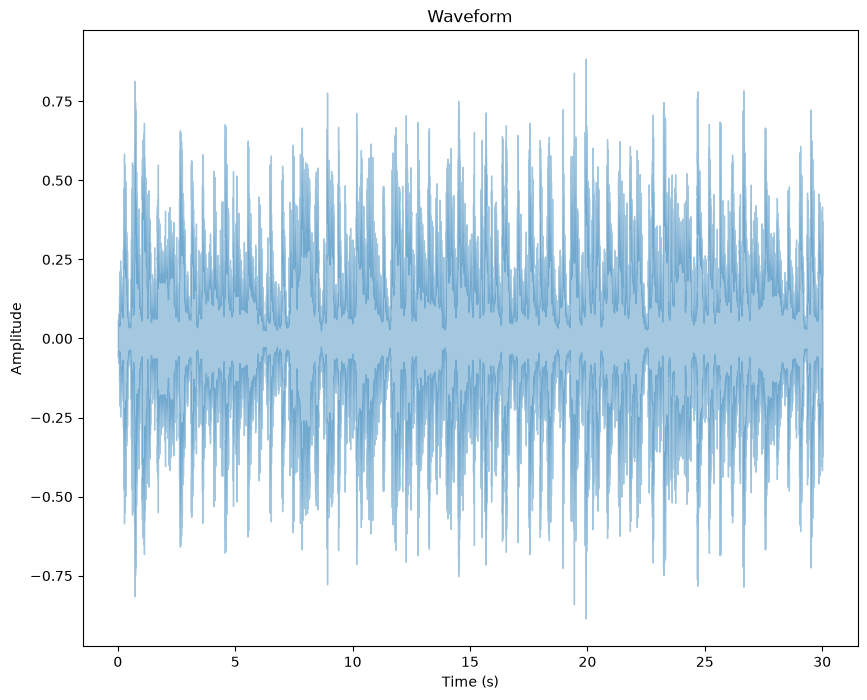

In [24]:
# WAVEFORM

plt.figure(figsize=FIG_SIZE)

librosa.display.waveshow(y=signal, sr=sample_rate, alpha=0.4)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Waveform")

plt.show()

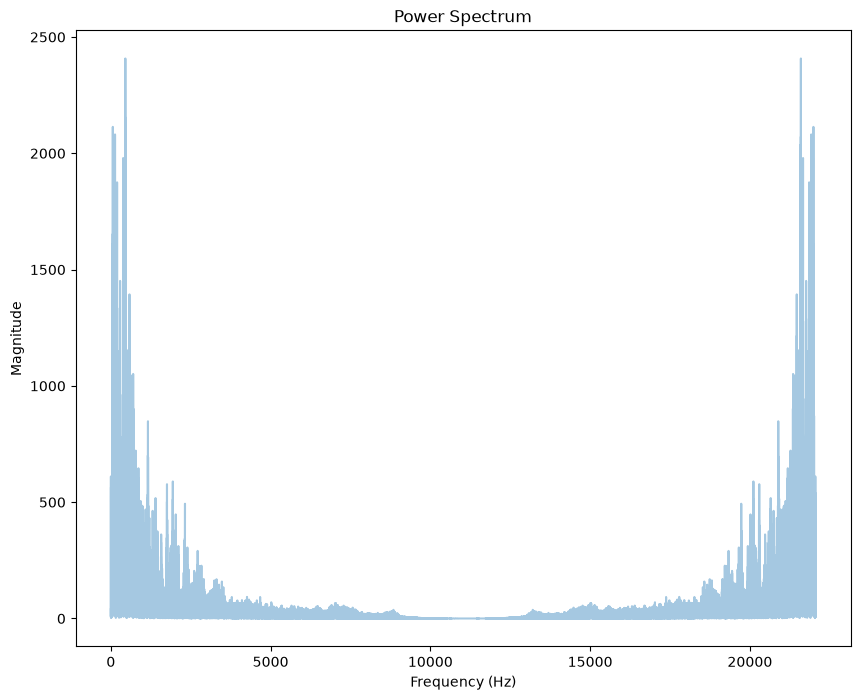

In [25]:
# FFT -> Power Spectrum

# Perform Fourier Transform
fft = np.fft.fft(signal)

# Calculate magnitude
spectrum = np.abs(fft)

# Create frequency variable
f = np.linspace(0, sample_rate, len(spectrum))

# Plot spectrum
plt.figure(figsize=FIG_SIZE)

plt.plot(f, spectrum, alpha=0.4)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Power Spectrum")

plt.show()

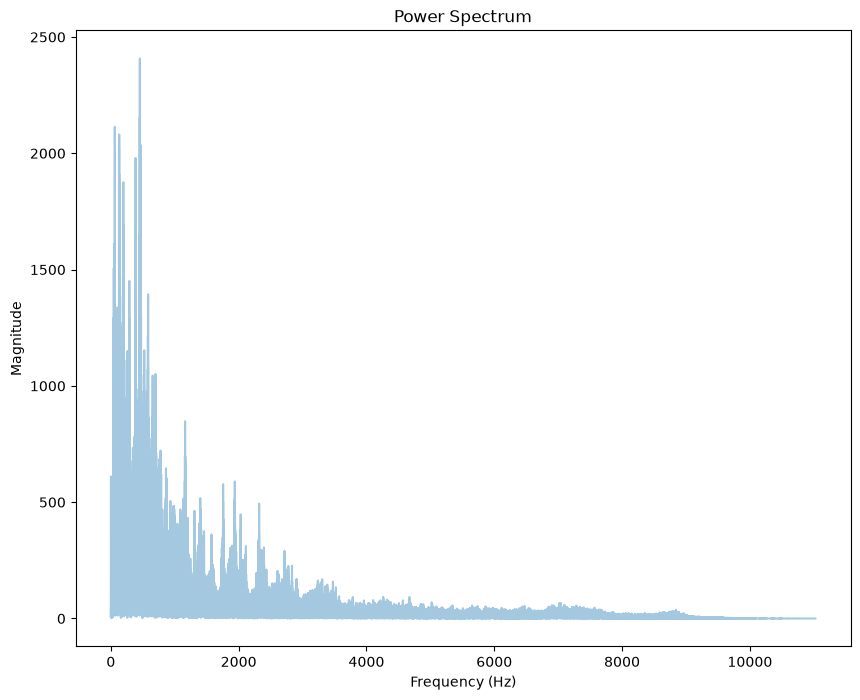

In [26]:
# Take half of the spectrum and frequency

left_spectrum = spectrum[:int(len(spectrum) / 2)]
left_f = f[:int(len(f) / 2)]

# Plot spectrum
plt.figure(figsize=FIG_SIZE)

plt.plot(left_f, left_spectrum, alpha=0.4)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Power Spectrum")

plt.show()

In [27]:
# Short Time Fourier Transform (STFT)

hop_length = 512
n_fft = 2048

# Calculate duration in seconds
hop_length_duration = float(hop_length) / sample_rate
n_fft_duration = float(n_fft) / sample_rate

print("Hop Length Duration:", hop_length_duration, "seconds")
print("FFT Window Duration:", n_fft_duration, "seconds")

Hop Length Duration: 0.023219954648526078 seconds
FFT Window Duration: 0.09287981859410431 seconds


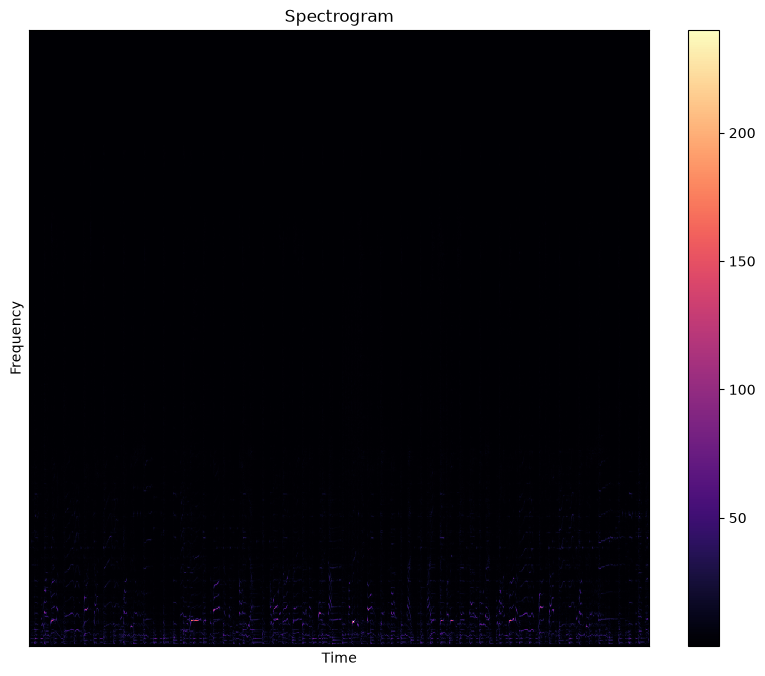

In [28]:
# Perform STFT

stft = librosa.stft(signal, n_fft=n_fft, hop_length=hop_length)

# Calculate magnitude
spectrogram = np.abs(stft)

# Display spectrogram
plt.figure(figsize=FIG_SIZE)

librosa.display.specshow(spectrogram, sr=sample_rate, hop_length=hop_length)

plt.xlabel("Time")
plt.ylabel("Frequency")
plt.colorbar()
plt.title("Spectrogram")

plt.show()

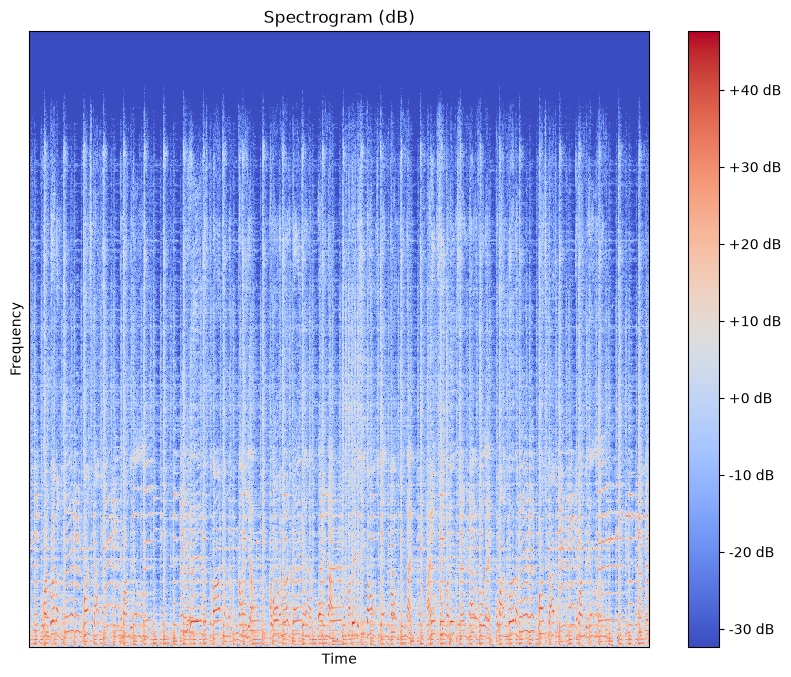

In [29]:
# Convert amplitude to Decibels

log_spectrogram = librosa.amplitude_to_db(spectrogram)

plt.figure(figsize=FIG_SIZE)

librosa.display.specshow(log_spectrogram, sr=sample_rate, hop_length=hop_length)

plt.xlabel("Time")
plt.ylabel("Frequency")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram (dB)")

plt.show()

In [30]:
# MFCCs

# Extract 13 MFCCs
MFCCs = librosa.feature.mfcc(y=signal, sr=sample_rate, n_fft=n_fft, hop_length=hop_length, n_mfcc=13)

print("MFCC Shape:", MFCCs.shape)

MFCC Shape: (13, 1293)


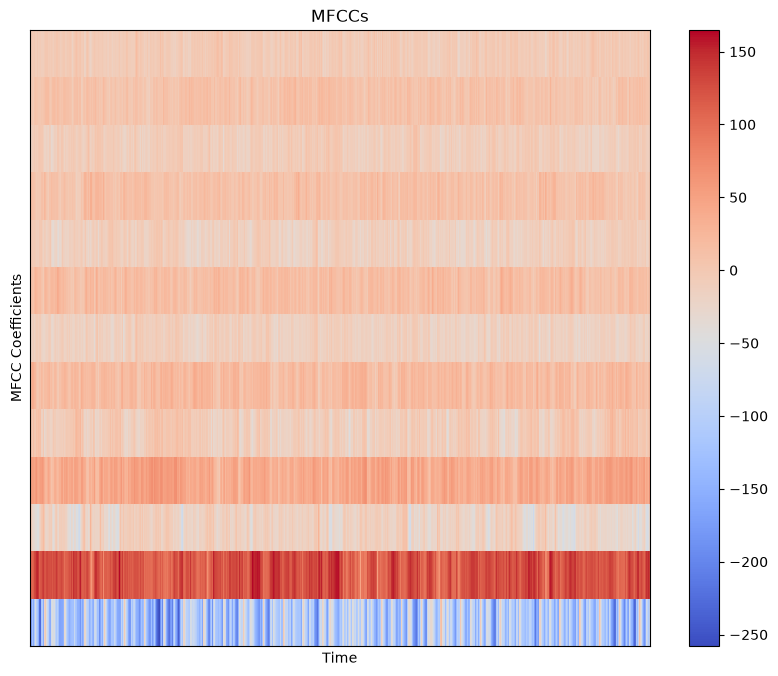

In [31]:
# Display MFCCs

plt.figure(figsize=FIG_SIZE)

librosa.display.specshow(MFCCs, sr=sample_rate, hop_length=hop_length)

plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")
plt.colorbar()
plt.title("MFCCs")

plt.show()